# Step 1 · The data

**Goal:** load the historical experiments and understand what we have to work with.

We use the data from Cosenza et al. (2022): C2C12 mouse muscle cells, media built from 14 components. We keep only the **25 recipes measured with the expensive, reliable assay** (cell count after two passages, "Passage 2"). The paper's cheaper assays are left out to keep the approach simple; the memo discusses how they could be used.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from mediaopt.data import COMPONENTS, COLS, MAX_CONC, load_recipes

df = load_recipes()
print(df.shape)
df.round(2).head()

(25, 16)


,T,I,SS,AA,Glu,Gluta,Albu,FBS,H,D,P,Esd,Ethan,Glutath,y,y_var
0,0.85,0.85,0.59,0.67,0.39,0.24,0.47,0.65,0.16,0.76,0.82,0.22,0.35,0.21,-1.33,0.14
1,0.57,0.57,0.62,0.71,0.51,0.32,0.06,0.47,0.91,0.52,0.76,0.08,0.99,0.35,-1.60,0.01
2,0.34,0.34,0.43,0.99,0.81,0.72,0.70,0.89,0.32,0.99,0.22,0.14,0.50,0.82,0.23,0.56
3,0.00,0.00,0.00,1.00,1.00,1.00,0.00,0.00,0.00,0.00,0.00,0.89,1.00,0.00,-1.63,0.00
4,1.00,0.00,0.00,0.00,1.00,1.00,0.00,0.00,0.00,0.00,1.00,0.00,0.18,0.00,-1.63,0.00


**Columns**
- `T` … `Glutath`: amount of each of the 14 components, scaled 0-1 (0 = none, 1 = the maximum allowed concentration).
- `y`: cell count, standardised (mean 0, sd 1). Higher means more cells. The original units are not in the published data.
- `y_var`: variance between replicate wells, i.e. measurement noise.

The published files have no column names; we reconstructed them from the paper. **Check:** the best recipe in the data should match the optimal medium the paper reports (Table 3).

In [2]:
paper_optimum = pd.Series({"T": 2.16e-2, "I": 2.27e-2, "SS": 6.34e-6, "AA": 0, "Glu": 8.97, "Gluta": 1.32, "Albu": 0,
                           "FBS": 10.1, "H": 0, "D": 0, "P": 1.75e-5, "Esd": 8.75e-6, "Ethan": 3.64e-3, "Glutath": 2.49e-3})
best = df.loc[df.y.idxmax(), COLS]
pd.DataFrame({"paper optimum (scaled)": paper_optimum / MAX_CONC, "best recipe in data": best}).T.round(2)

,T,I,SS,AA,Glu,Gluta,Albu,FBS,H,D,P,Esd,Ethan,Glutath
paper optimum (scaled),0.83,0.65,0.36,0.0,0.57,0.87,0.0,0.58,0.0,0.0,1.0,1.0,0.55,0.71
best recipe in data,0.82,0.65,0.36,0.0,0.57,0.87,0.0,0.57,0.0,0.0,1.0,1.0,0.55,0.71


They match, so the column order is right.

**How noisy are the measurements?** Compare the spread between replicate wells (noise) with the spread between recipes (signal).

In [3]:
noise_sd = df.y_var.median() ** 0.5
print(f"typical noise (sd between replicate wells): {noise_sd:.2f}")
print(f"spread between recipes (sd of y):            {df.y.std():.2f}")

typical noise (sd between replicate wells): 0.21
spread between recipes (sd of y):            1.30


**Growth versus each component.** Each dot is one recipe.

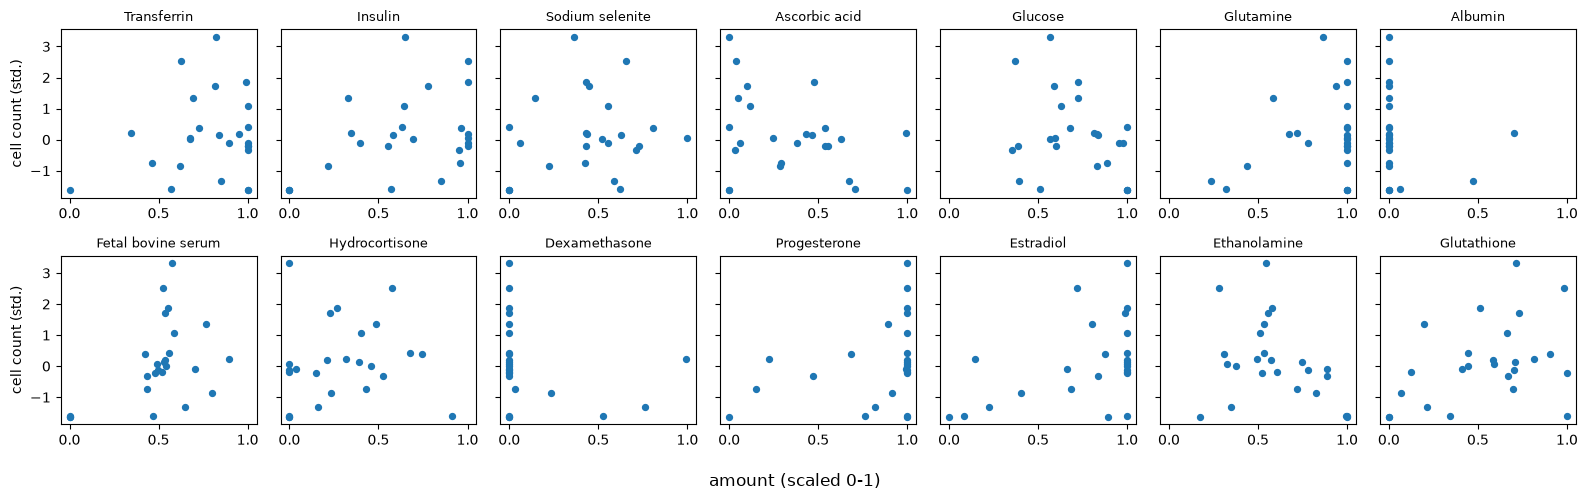

In [4]:
names = {abbrev: name for abbrev, name, *_ in COMPONENTS}
fig, axes = plt.subplots(2, 7, figsize=(16, 5), sharey=True)
for ax, col in zip(axes.flat, COLS):
    ax.scatter(df[col], df.y, s=18)
    ax.set_title(names[col], fontsize=9)
    ax.set_xlim(-0.05, 1.05)
for ax in axes[:, 0]:
    ax.set_ylabel("cell count (std.)")
fig.supxlabel("amount (scaled 0-1)")
fig.tight_layout()
plt.show()

**Takeaways**
- **Very little data:** 25 recipes for 14 components, fewer than 2 experiments per component. A model with all pairwise interactions would need over 100 coefficients. So we need a model that works with few points and tells us how unsure it is (step 3).
- **Measurements are reliable:** noise between replicate wells (sd ≈ 0.2) is small compared with differences between recipes (sd ≈ 1.3). Differences between recipes are real, not noise.
- **Visible patterns:**
  - No FBS means poor growth, and the best recipes sit around the middle (≈ 0.55, about 10 % serum).
  - The best recipes have no albumin and no dexamethasone.
  - Glutamine and progesterone are at their maximum in most good recipes.
- **Caution:** these are not random samples. The authors' algorithm chose later recipes near earlier good ones, so the patterns partly reflect where they looked. No single component explains growth on its own, so the model must use all 14 together.